# Customer Offer Response Predictive Modeling

Which customers respond to which Starbucks offers — and can we predict whether a customer will complete an offer they received?

This notebook is the narrative summary of the project. All logic lives in the `offer_response` package under `src/`; the full pipeline runs with `python run_pipeline.py` from the repo root. This is a 2026 rebuild of a 2022 Udacity capstone notebook — see the README for what changed.

## 1. Load the data

Three JSON-lines files, read straight from `data.zip`: 10 offers, 17,000 customers, 306,534 events.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path('..').resolve() / 'src'))

from offer_response import analysis, cleaning, data, features, modeling, plotting

portfolio_raw, profile_raw, transcript_raw = data.load_raw()
print(f"portfolio:  {portfolio_raw.shape}")
print(f"profile:    {profile_raw.shape}")
print(f"transcript: {transcript_raw.shape}")

portfolio:  (10, 6)
profile:    (17000, 5)
transcript: (306534, 4)


## 2. Clean the tables

- Offers: channel lists become binary columns; duration goes from days to hours.
- Customers: `m_days` (membership tenure) is measured against the latest join date in the data, so it is reproducible.
- Transcript: the `value` dict is expanded vectorised into `offer_id`, `amount` (kept as float) and `reward`.

In [2]:
portfolio = cleaning.clean_portfolio(portfolio_raw)
profile = cleaning.clean_profile(profile_raw)
transcript = cleaning.parse_transcript(transcript_raw)
master = features.build_master_table(transcript, portfolio, profile)
print(f"master table: {master.shape[0]:,} rows x {master.shape[1]} columns")
print(f"customers with unknown demographics (age 118): "
      f"{cleaning.count_missing_demographics(profile):,}")
master.head()

master table: 306,534 rows x 18 columns
customers with unknown demographics (age 118): 2,175


,customer_id,offer_id,event,gender,age,income,offer_type,difficulty,m_days,start_h,duration_h,reward_expected,reward_received,amount,email,mobile,social,web
0,78afa995795e4d85b5d9ceeca43f5fef,9b98b8c7a33c4b65b9aebfe6a799e6d9,offer received,F,75,100000.0,bogo,5.0,443,0,168.0,5.0,0,0.0,1.0,1.0,0.0,1.0
1,a03223e636434f42ac4c3df47e8bac43,0b1e1539f2cc45b7b9fa7c272da2e1d7,offer received,NaN,118,NaN,discount,20.0,356,0,240.0,5.0,0,0.0,1.0,0.0,0.0,1.0
2,e2127556f4f64592b11af22de27a7932,2906b810c7d4411798c6938adc9daaa5,offer received,M,68,70000.0,discount,10.0,91,0,168.0,2.0,0,0.0,1.0,1.0,0.0,1.0
3,8ec6ce2a7e7949b1bf142def7d0e0586,fafdcd668e3743c1bb461111dcafc2a4,offer received,NaN,118,NaN,discount,10.0,304,0,240.0,2.0,0,0.0,1.0,1.0,1.0,1.0
4,68617ca6246f4fbc85e91a2a49552598,4d5c57ea9a6940dd891ad53e9dbe8da0,offer received,NaN,118,NaN,bogo,10.0,297,0,120.0,10.0,0,0.0,1.0,1.0,1.0,1.0


## 3. Key findings

Discount offers complete more often than BOGO offers, and most customers who transact have completed at least one offer.

In [3]:
findings = analysis.summarize(master, portfolio, profile, transcript)
print(f"Events: {findings['dataset']['events_by_type']}")
print(f"Completion rate (bogo + discount): "
      f"{findings['offer_completion']['completion_rate']:.1%}")
for offer_type, stats in findings['offer_completion']['by_offer_type'].items():
    print(f"  {offer_type:9s}: {stats['completion_rate']:.1%} "
          f"({stats['completed']:,} / {stats['received']:,})")
print(f"Informational view rate: "
      f"{findings['informational_offers']['view_rate']:.1%}")
print(f"Customer segments: {findings['customer_segments']}")

Events: {'transaction': 138953, 'offer received': 76277, 'offer viewed': 57725, 'offer completed': 33579}
Completion rate (bogo + discount): 55.0%
  bogo     : 51.4% (15,669 / 30,499)
  discount : 58.6% (17,910 / 30,543)
Informational view rate: 71.1%
Customer segments: {'completed_and_transacted': 12774, 'transacted_never_completed': 3804, 'offer_activity_no_transaction': 422, 'transacted_no_offer': 6, 'total_customers_in_transcript': 17000}


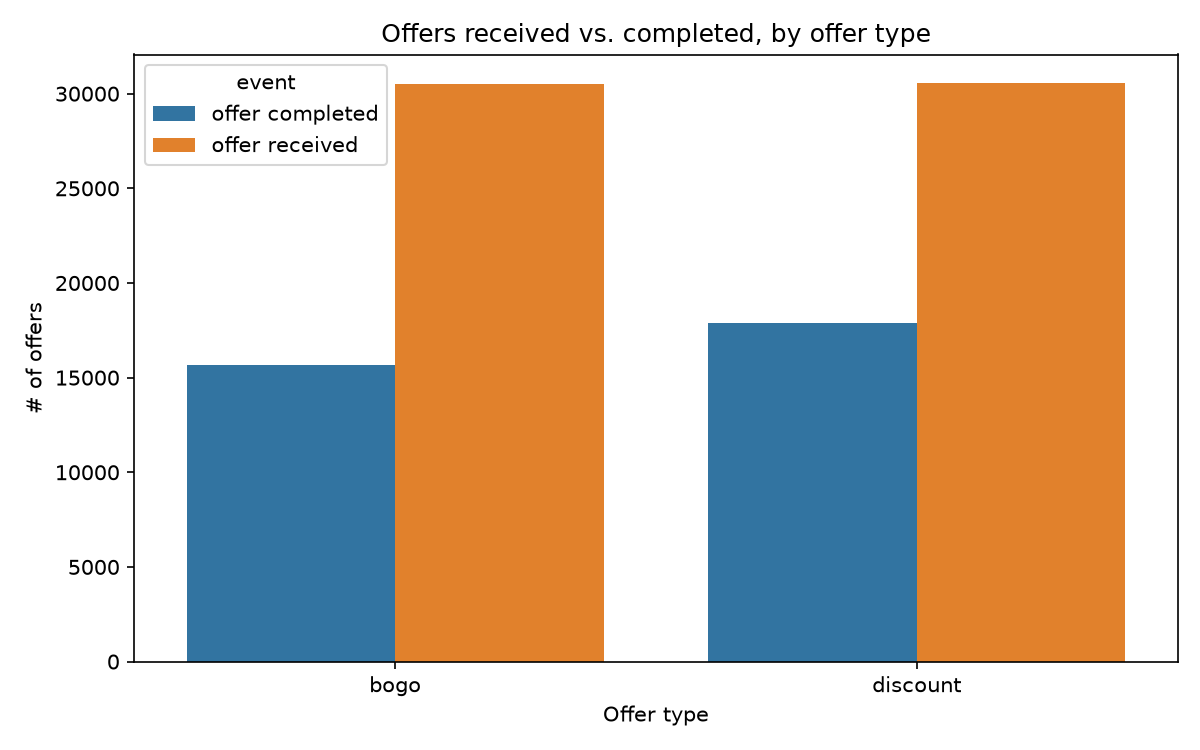

In [4]:
from IPython.display import Image

figures = Path('../outputs/figures')
figures.mkdir(parents=True, exist_ok=True)
plotting.plot_completion_by_offer_type(master, figures / 'completion_by_offer_type.png')
Image(str(figures / 'completion_by_offer_type.png'))

## 4. Modeling: will this customer complete the offer?

Target: 1 for `offer completed` rows, 0 for `offer received` rows (bogo/discount only — informational offers have no completion event). Features describe the customer (age, income, tenure, gender) and the offer (type, difficulty, reward, duration, channels).

In [5]:
X, y, _ = features.build_modeling_frame(master)
print(f"Modeling frame: {X.shape[0]:,} rows, {X.shape[1]} features, "
      f"positive rate {y.mean():.3f}")
models, metrics, split = modeling.train_and_evaluate(X, y)
print(f"Train: {split['train_rows']:,} rows, test: {split['test_rows']:,} rows")
import pandas as pd
pd.DataFrame(metrics).T

Modeling frame: 94,621 rows, 15 features, positive rate 0.355


Train: 75,696 rows, test: 18,925 rows


,jaccard,f1_weighted,log_loss,accuracy,roc_auc
logistic_regression,0.071,0.5465,0.6271,0.6417,0.6200
decision_tree,0.000,0.5060,0.6203,0.6451,0.6274


## 5. What the scores mean

Both models beat the majority-class baseline on ROC AUC (~0.62) but the positive-class Jaccard is low — the decision tree predicts no completions at all. That is a property of the task framing, not just the models: an offer that gets completed appears twice in the data, once as a received row (label 0) and once as a completed row (label 1), with identical features. 28,996 of 50,637 distinct (customer, offer) pairs carry both labels, so the classes are not separable from these features alone.

Note on the 2022 numbers: the original notebook reported Jaccard 0.64 / 0.65, but the removed sklearn function it used reduced to accuracy on single-label data — those figures are accuracy (reproduced here: 0.64 / 0.65). The modern positive-class Jaccard is 0.07 / 0.00.

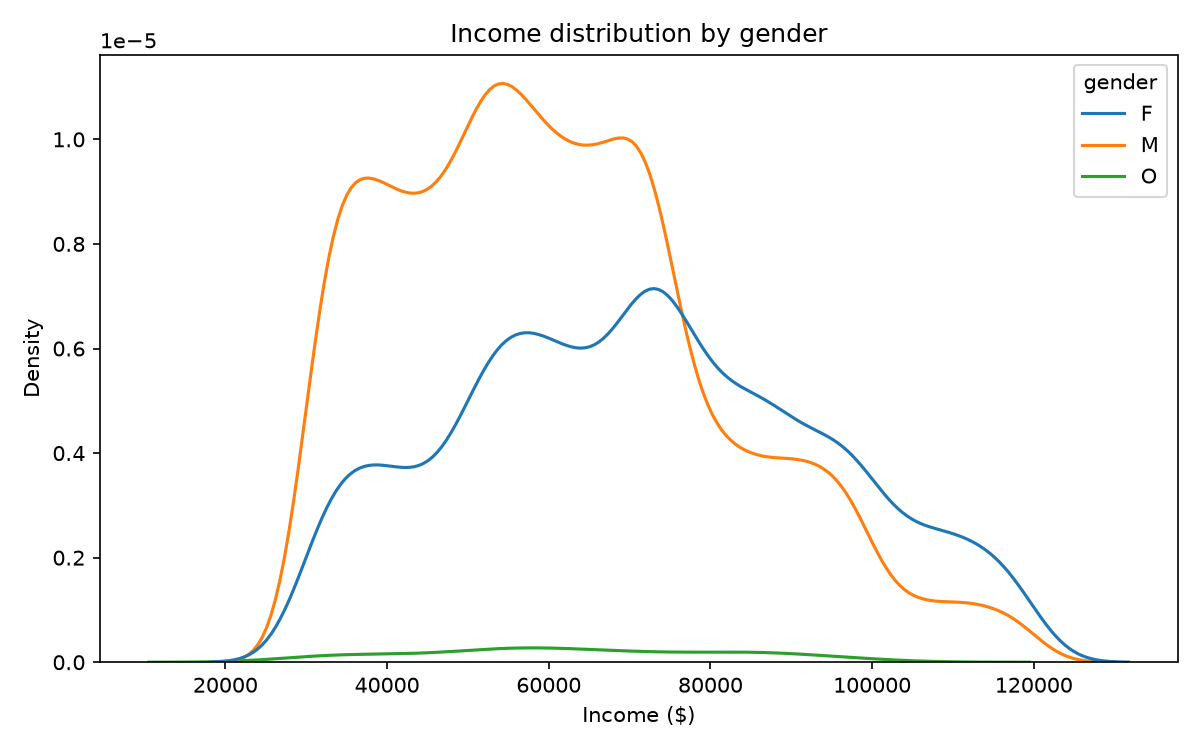

In [6]:
plotting.plot_income_by_gender(profile, figures / 'income_by_gender.png')
Image(str(figures / 'income_by_gender.png'))